# 응용 06. BatchNorm 유무와 40·80·128 epoch 비교

2026-10-30 실습 기록 · 원본: `../06_batchnorm.py`


## 0. 준비와 기록의 범위
pandas와 IPython이 설치된 커널에서 위에서 아래로 실행합니다. 저장소 루트, `02_응용`, `docs`에서 실행할 수 있습니다.

추가된 **40·80·128 epoch별 실제 CSV와 그래프**를 각각 읽어 비교합니다. 128 epoch 기록을 잘라서 대신 사용하는 방식에서 epoch별 저장 파일을 사용하는 방식으로 변경했습니다.

각 실행의 BatchNorm 유무별 history CSV 총 6개에서 best epoch, best valid loss, 마지막 train·valid loss를 계산합니다. 그래프도 각 실행에 대응하는 PNG 총 6개를 표시합니다. 원본 학습은 재실행하지 않습니다.


In [1]:
from pathlib import Path
import pandas as pd

candidates = [Path.cwd(), Path.cwd().parent, Path.cwd() / "20261030" / "02_응용"]
base = next((p for p in candidates if (p / "06_batchnorm.py").is_file()), None)
if base is None:
    raise FileNotFoundError("저장소 루트, 02_응용 또는 docs에서 실행하세요.")
base = base.resolve()
out = base / "outputs"
histories = {}
for epochs in (40, 80, 128):
    histories[epochs] = {}
    for bn, state in ((False, "disabled"), (True, "enabled")):
        csv_path = out / f"06_{epochs}baseline_{state}_history.csv"
        history = pd.read_csv(csv_path)
        if history["epoch"].tolist() != list(range(1, epochs + 1)):
            raise ValueError(f"{csv_path.name}: epoch 범위를 확인하세요.")
        histories[epochs][bn] = history
        print(f"{epochs} epochs / BatchNorm={bn}: {csv_path.name} ({len(history)}행)")


40 epochs / BatchNorm=False: 06_40baseline_disabled_history.csv (40행)
40 epochs / BatchNorm=True: 06_40baseline_enabled_history.csv (40행)
80 epochs / BatchNorm=False: 06_80baseline_disabled_history.csv (80행)
80 epochs / BatchNorm=True: 06_80baseline_enabled_history.csv (80행)
128 epochs / BatchNorm=False: 06_128baseline_disabled_history.csv (128행)
128 epochs / BatchNorm=True: 06_128baseline_enabled_history.csv (128행)


## 1. BatchNorm 유무의 차이
| 구분 | bn=False | bn=True |
| --- | --- | --- |
| 구조 | Linear → ReLU | Linear → BatchNorm1d(32) → ReLU |
| 적용 위치 | 없음 | 두 은닉층의 Linear 뒤 |
| 학습 모드 | BN 정규화 없음 | 현재 mini-batch의 특성별 평균·분산으로 정규화, running 통계 갱신 |
| 평가 모드 | BN 정규화 없음 | 누적된 running_mean·running_var로 정규화 |
| 추가 학습 파라미터 | 없음 | 특성별 배율 γ와 이동 β |

BatchNorm은 은닉층 활성값의 분포를 조정합니다. 학습을 안정시키는 데 도움이 될 수 있지만 검증 손실 개선을 보장하지는 않습니다. 작은 batch, batch 구성, running 통계, 학습률에 영향을 받습니다.

고정 조건은 CPU, 은닉층 폭 32, AdamW(lr=0.01, weight_decay=0), Dropout p=0, batch_size=32, 모델 seed=42, shuffle Generator seed=43입니다. 후보마다 모델·Optimizer·DataLoader를 새로 만듭니다. 마지막 16개 batch도 학습하며 BN의 학습 batch는 2개 이상입니다.

BN을 추가하면 γ·β도 학습하므로 두 후보의 전체 파라미터 수는 달라집니다. 입력 2 → 은닉 32 → 은닉 32 → 출력 2의 구조에서 BN 없는 모델은 1,218개, BN 있는 모델은 1,346개입니다.


## 2. train·valid 데이터와 train()·eval() 모드
| 용어 | 의미 | 가중치 갱신 여부 |
| --- | --- | --- |
| train 데이터 | 가중치를 학습하는 자료 | 학습 루프에서 backward·step 수행 |
| valid 데이터 | 학습 중 일반화 성능과 best epoch를 판단하는 자료 | 갱신하지 않음 |
| model.train() | BN이 현재 batch 통계를 쓰고 running 통계를 갱신하는 모드 | 모드 자체가 역전파·step을 실행하지 않음 |
| model.eval() | BN이 저장된 running 통계를 쓰는 모드 | 기울기 계산을 자동으로 끄지는 않음 |

데이터 구분과 모델 모드는 별개입니다. 이 실습은 epoch 종료 후 **train 데이터와 valid 데이터 모두 eval 모드 + no_grad로 측정**합니다.

- `train_loss_eval`: 갱신된 모델이 학습 자료에 얼마나 잘 맞는지 측정한 손실
- `valid_loss`: 같은 모델이 학습에 사용하지 않은 검증 자료에 얼마나 잘 맞는지 측정한 손실

두 값은 같은 모드에서 계산하므로 비교하기 좋습니다. valid가 train보다 항상 커야 하는 것은 아닙니다. 데이터의 크기·난이도 차이 때문에 valid가 더 작을 수도 있습니다. 학습 중 mini-batch에서 얻은 손실과 `train_loss_eval`도 구분합니다.

`no_grad()`만 사용해도 train 모드 BN의 running 통계는 갱신될 수 있습니다. 검증에서는 `eval()`도 호출해야 합니다. test는 모델·epoch 선택에 사용하지 않습니다.


## 3. 40·80·128 epoch 결과표

각 구간에서 valid_loss가 최소인 행을 찾았습니다. best epoch는 구간의 마지막 epoch나 최고 정확도 epoch를 의미하지 않습니다.

| epochs | batchnorm | best_epoch | best_valid_loss | valid_acc_at_best |
| --- | --- | --- | --- | --- |
| 40 | False | 38 | 0.016560 | 1.000000 |
| 40 | True | 21 | 0.032904 | 1.000000 |
| 80 | False | 78 | 0.006114 | 1.000000 |
| 80 | True | 21 | 0.032904 | 1.000000 |
| 128 | False | 107 | 0.004557 | 1.000000 |
| 128 | True | 121 | 0.030689 | 1.000000 |

`valid_acc_at_best`는 0~1 비율입니다. 이번에는 모두 1.0(100%)이지만 교차 엔트로피 손실은 다릅니다. 정확한 분류 여부가 같아도 예측 확신도에 따라 손실이 달라질 수 있습니다.


In [2]:
rows = []
for epochs, candidates in histories.items():
    for bn, window in candidates.items():
        best = window.loc[window["valid_loss"].idxmin()]
        last = window.iloc[-1]
        rows.append({"epochs": epochs, "batchnorm": bn,
                     "best_epoch": int(best["epoch"]),
                     "best_valid_loss": best["valid_loss"],
                     "valid_acc_at_best": best["valid_acc"],
                     "train_at_best": best["train_loss_eval"],
                     "last_train_loss_eval": last["train_loss_eval"],
                     "last_valid_loss": last["valid_loss"]})
comparison = pd.DataFrame(rows)
comparison.to_csv(out / "06_epoch_comparison.csv", index=False)
print(comparison.to_string(index=False, float_format=lambda x: f"{x:.6f}"))


 epochs  batchnorm  best_epoch  best_valid_loss  valid_acc_at_best  train_at_best  last_train_loss_eval  last_valid_loss
     40      False          38         0.016560           1.000000       0.018079              0.016876         0.020212
     40       True          21         0.032904           1.000000       0.053328              0.055871         0.041528
     80      False          78         0.006114           1.000000       0.016391              0.079643         0.036195
     80       True          21         0.032904           1.000000       0.053328              0.043082         0.041777
    128      False         107         0.004557           1.000000       0.011569              0.005645         0.005913
    128       True         121         0.030689           1.000000       0.047919              0.037431         0.040882


### 결과의 근거와 해석
- **40 epochs:** BN 없음은 38 epoch에서 0.016560, BN 있음은 21 epoch에서 0.032904입니다. BN 모델이 더 이른 시점에 최솟값을 기록했지만, 그 값이 더 낮지는 않습니다. best가 일찍 나왔다는 것만으로 수렴 속도가 더 빠르다고 단정하지 않습니다.
- **80 epochs:** BN 없음은 78 epoch에서 0.006114로 개선했습니다. BN 있음은 21 epoch의 0.032904가 그대로 최소값입니다. 이 실행에서는 41~80 epoch를 추가해도 BN 모델의 기존 최소값을 경신하지 못했습니다.
- **128 epochs:** BN 없음은 107 epoch에서 0.004557, BN 있음은 121 epoch에서 0.030689입니다. BN 모델도 80 epoch 이후에 기존 최솟값을 경신했지만 BN 없는 모델보다 검증 손실이 큽니다.

근거 파일은 `06_{40,80,128}baseline_{disabled,enabled}_history.csv` 총 6개이며, 각 파일을 개별 분석한 요약은 `06_epoch_comparison.csv`입니다. README의 예상 예시와 실제 CSV의 소수점 값이 약간 다를 수 있어 이번 기록은 CSV를 기준으로 작성했습니다.

관찰 범위를 늘릴수록 **누적 최소값은 증가할 수 없습니다.** 후보 epoch가 늘어난 결과이므로 최소값 감소만으로 긴 학습이 항상 더 좋다고 주장할 수 없습니다. 아래의 마지막 손실도 함께 확인해야 합니다. 또한 여러 종료 시점을 비교한 사실을 기록하고, test를 이용해 종료 시점을 고르지 않습니다.


## 4. best 이후 train·valid 변화와 과적합 가능성

| epochs | batchnorm | train_at_best | last_train_loss_eval | best_valid_loss | last_valid_loss |
| --- | --- | --- | --- | --- | --- |
| 40 | False | 0.018079 | 0.016876 | 0.016560 | 0.020212 |
| 40 | True | 0.053328 | 0.055871 | 0.032904 | 0.041528 |
| 80 | False | 0.016391 | 0.079643 | 0.006114 | 0.036195 |
| 80 | True | 0.053328 | 0.043082 | 0.032904 | 0.041777 |
| 128 | False | 0.011569 | 0.005645 | 0.004557 | 0.005913 |
| 128 | True | 0.047919 | 0.037431 | 0.030689 | 0.040882 |

- **BN 없음, 40:** 38→40에서 train은 0.018079→0.016876으로 줄고 valid는 0.016560→0.020212로 증가합니다. 과적합 가능성과 일치하지만 2 epoch의 짧은 관찰입니다.
- **BN 없음, 80:** 78→80에서 train·valid가 모두 증가합니다. 전형적인 과적합 패턴 외에도 학습 변동이나 최적화 불안정 가능성을 고려합니다.
- **BN 없음, 128:** 107→128에서 train은 0.011569→0.005645로 줄고 valid는 0.004557→0.005913으로 증가합니다. 학습 자료에 더 맞추는 동안 검증 손실이 악화되는 과적합 가능성이 있습니다.
- **BN 있음, 40:** 21→40에서 둘 다 증가합니다. 이것만으로 과적합을 단정하기 어렵습니다.
- **BN 있음, 80:** 21→80에서 train은 0.053328→0.043082로 줄고 valid는 0.032904→0.041777로 증가합니다. 과적합 가능성을 점검할 신호입니다. 다만 128 epoch 기록에서는 121 epoch에 더 낮은 valid loss가 나타나므로 21 이후 내내 악화했다고 말할 수 없습니다.
- **BN 있음, 128:** 121→128에서 train은 0.047919→0.037431로 줄고 valid는 0.030689→0.040882로 증가합니다. 이 구간 역시 과적합 가능성과 일치합니다.

위 비교는 **best와 구간 마지막 지점의 차이**입니다. 중간의 모든 epoch가 단조롭게 변했다는 뜻은 아닙니다. 그래프와 전체 CSV로 추세·출렁임을 함께 확인하고 여러 seed에서 반복해야 합니다. BN running 통계의 변동도 평가 손실에 영향을 줄 수 있습니다.

원본은 Early Stopping이나 best 가중치 저장·복원을 수행하지 않습니다. best를 표에 적어도 실행 종료 시 모델은 128 epoch 상태입니다.


## 5. 40·80·128 epoch별 학습곡선
각 실행에 대응하는 저장 PNG를 표시합니다. 같은 epoch 안에서 BatchNorm 없음·있음 순서로 비교합니다. 가로축은 epoch, 세로축은 손실이며 train은 epoch 종료 후 eval 모드에서 측정한 학습 데이터 손실입니다. 점선은 **해당 실행 범위 안에서** valid loss가 가장 낮은 epoch입니다.

파일 이름은 `06_{epochs}_{epochs}baseline_{disabled,enabled}_curves.png`입니다. 축 범위가 그림마다 다를 수 있으므로 곡선 모양과 함께 결과표의 실제 수치를 비교합니다.


40 epochs / BatchNorm=False


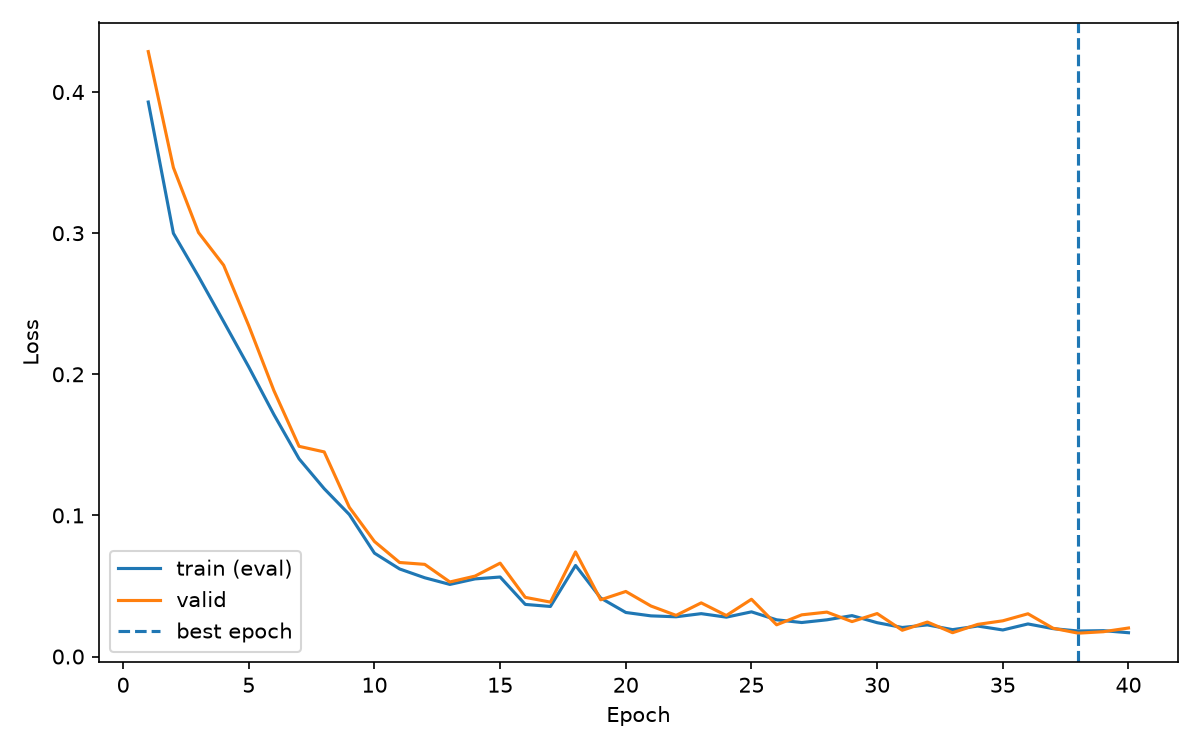

40 epochs / BatchNorm=True


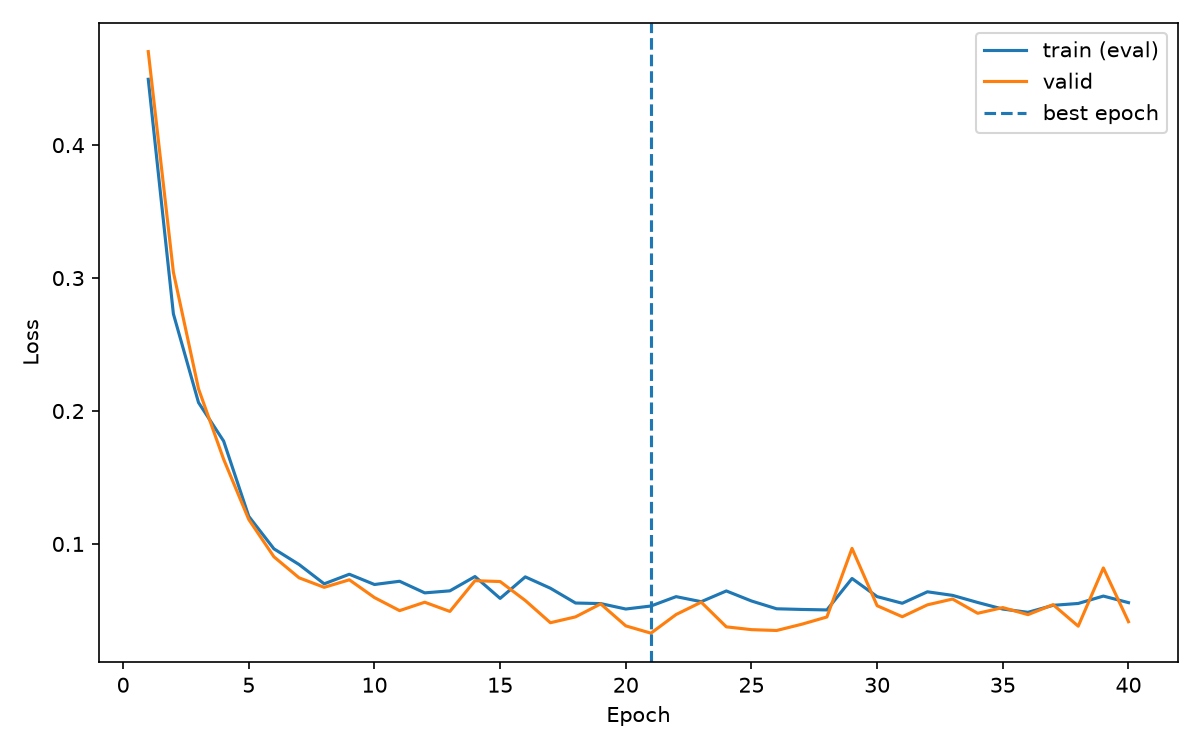

80 epochs / BatchNorm=False


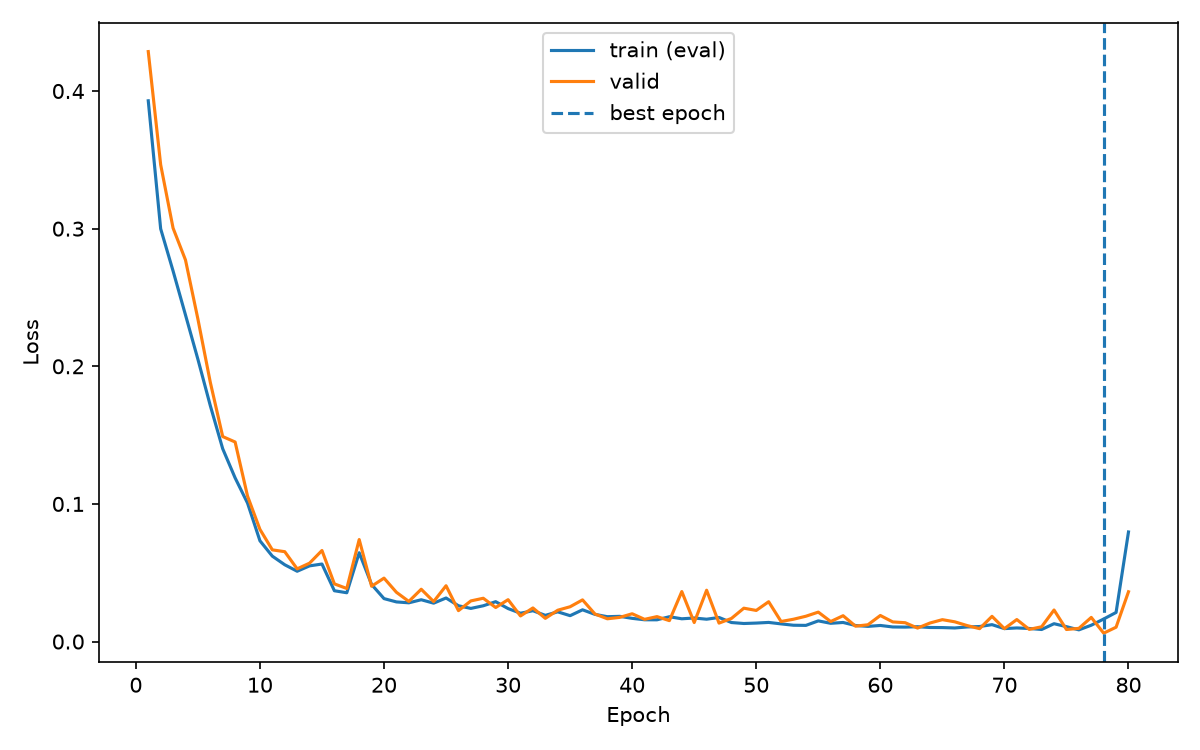

80 epochs / BatchNorm=True


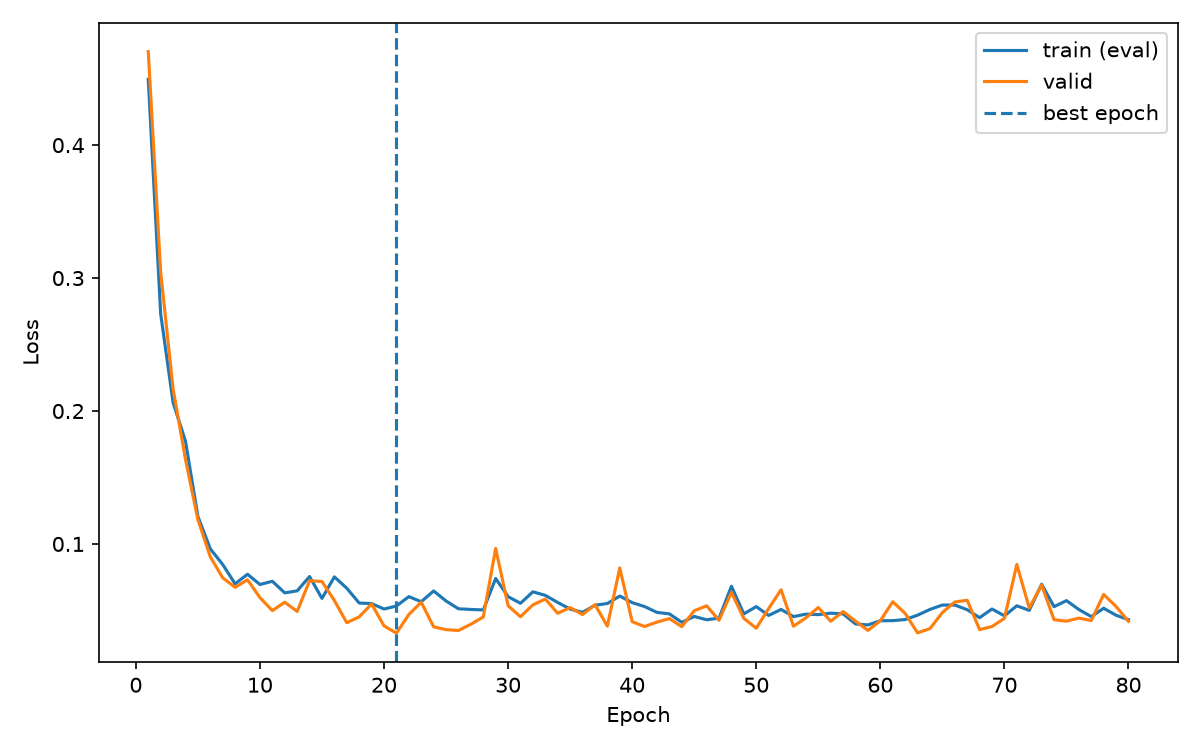

128 epochs / BatchNorm=False


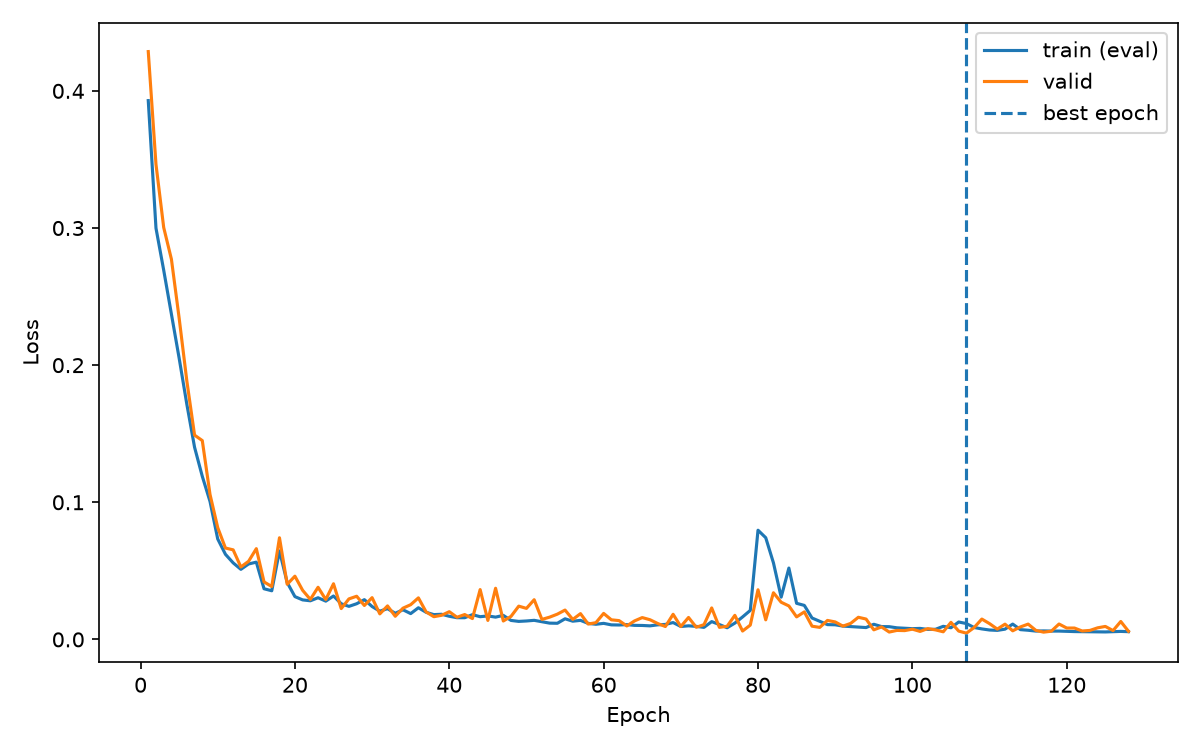

128 epochs / BatchNorm=True


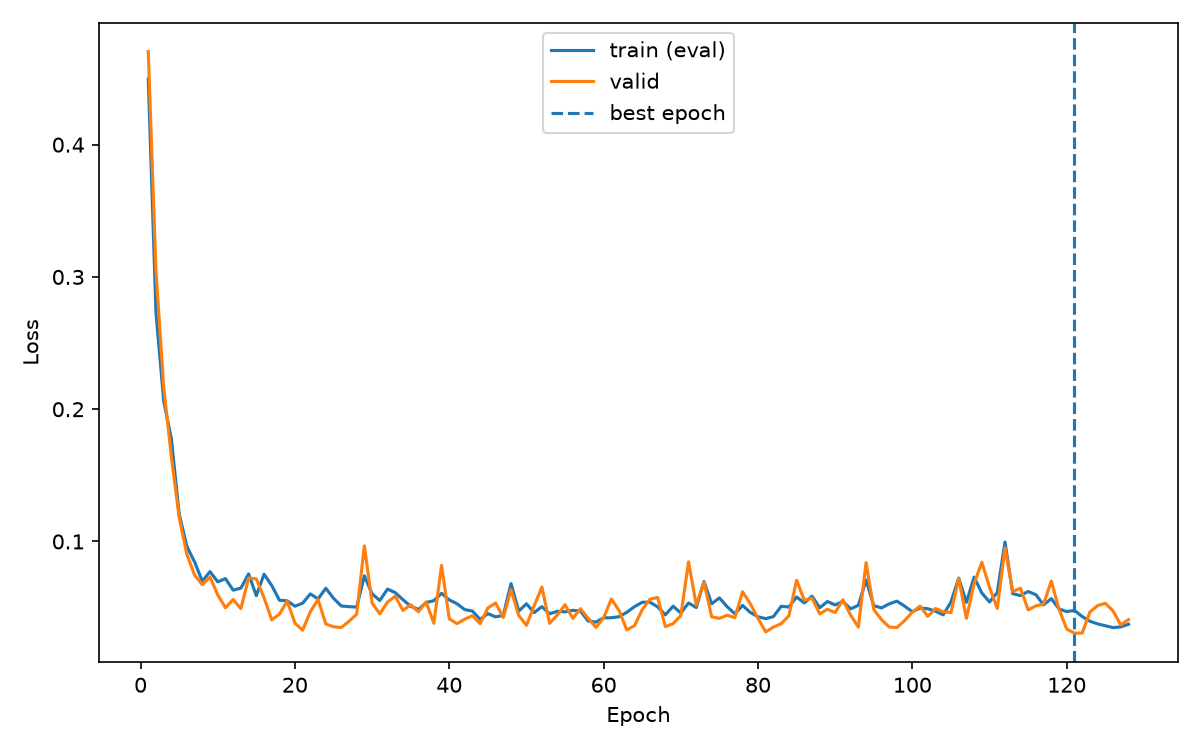

In [3]:
from IPython.display import Image, display
for epochs in (40, 80, 128):
    for bn, state in ((False, "disabled"), (True, "enabled")):
        print(f"{epochs} epochs / BatchNorm={bn}")
        image_path = out / f"06_{epochs}_{epochs}baseline_{state}_curves.png"
        display(Image(filename=str(image_path)))


## 6. 같은 입력도 train/eval 출력이 다른 이유
원본 마지막의 진단은 학습된 BN 모델을 복사해 동일한 32개 입력을 train 모드와 eval 모드에 각각 넣습니다. train에서는 그 32개의 batch 통계를, eval에서는 running 통계를 사용하므로 출력이 다를 수 있습니다. Dropout p=0이므로 이 진단에서는 Dropout 마스크 차이가 원인이 아닙니다.

진단의 train 호출은 `no_grad()` 안에서도 복사 모델의 running 통계를 갱신합니다. 따라서 이 실험은 고정된 원본 통계만으로 두 출력을 비교한 것은 아닙니다. 복사본을 쓰므로 원래 모델과 저장된 학습 기록은 바뀌지 않습니다. 최대 출력 차이가 크다는 사실만으로 성능이 나쁘다고 판단하지 않습니다.

### 완료 질문에 대한 답
BN은 기본 설정의 eval 모드에서 `running_mean`과 `running_var`를 사용합니다. 이번 batch size는 32이며 마지막 batch는 16개입니다. 이 동작은 `track_running_stats=True`인 현재 설정에 해당합니다.

이번 데이터·설정·단일 seed에서는 BN 없는 모델이 세 종료 시점 모두 더 낮은 best valid loss를 기록했습니다. 다른 데이터·batch size·학습률에서도 같은 결과가 나온다는 결론은 아닙니다.


## 7. 개인적 견해

BatchNorm 정규화를 통해 모델의 정확도와 손실이 개선되는 것을 기대 했으나, 오히려 BatchNorm을 적용하지 않은 모델이 더 낮은 진동 형상으로 관측됐습니다.

기존 epoch 값인 40으로 진행 했을 경우, BatchNorm을 적용하지 않은 모델에 대해 학습, 검증 손실률이 도중에 끊어지는 것 처럼 관측 됐습니다.
이러한 이유로 각각 epoch를 80, 128로 변경시켜 테스트를 진행 했으나, 검증 결과 80 Epoch의 BatchNorm을 미적용한 모델이 진동수가 가장 낮고, 이상적인 그래프를 따라 그려지는 것을 확인했습니다.

128의 경우, 동일하게 BatchNorm을 적용하지 않은 모델이 적용 한 모델보다 더욱 낮은 진동수를 보여줬으나, 80~90 사이의 값에서 값이 급격히 튀는 것이 관측됐습니다.

해당 결과를 기반으로 확인 했을 때 80Epoch의 BatchNorm을 미적용한 모델이 가장 이상적인 결과를 보인다고 판단했습니다.